In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore', category=UserWarning)

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix
from lightgbm import LGBMClassifier

file_path = "Loan_default.csv"
df = pd.read_csv(file_path)

print("Dataset loaded successfully! Shape:", df.shape)
df.head()

Dataset loaded successfully! Shape: (255347, 18)


,LoanID,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,Default
0,I38PQUQS96,56,85994,50587,520,80,4,15.23,36,0.44,Bachelor's,Full-time,Divorced,Yes,Yes,Other,Yes,0
1,HPSK72WA7R,69,50432,124440,458,15,1,4.81,60,0.68,Master's,Full-time,Married,No,No,Other,Yes,0
2,C1OZ6DPJ8Y,46,84208,129188,451,26,3,21.17,24,0.31,Master's,Unemployed,Divorced,Yes,Yes,Auto,No,1
3,V2KKSFM3UN,32,31713,44799,743,0,3,7.07,24,0.23,High School,Full-time,Married,No,No,Business,No,0
4,EY08JDHTZP,60,20437,9139,633,8,4,6.51,48,0.73,Bachelor's,Unemployed,Divorced,No,Yes,Auto,No,0


In [2]:
%pip install scikit-learn lightgbm pandas numpy matplotlib seaborn joblib

Note: you may need to restart the kernel to use updated packages.


In [3]:
print("Column Info:")
df.info()

print("\nMissing Values Per Column:")
print(df.isnull().sum())

print("\nTarget Variable Distribution:")
print(df['Default'].value_counts(normalize=True))

Column Info:
<class 'pandas.DataFrame'>
RangeIndex: 255347 entries, 0 to 255346
Data columns (total 18 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   LoanID          255347 non-null  str    
 1   Age             255347 non-null  int64  
 2   Income          255347 non-null  int64  
 3   LoanAmount      255347 non-null  int64  
 4   CreditScore     255347 non-null  int64  
 5   MonthsEmployed  255347 non-null  int64  
 6   NumCreditLines  255347 non-null  int64  
 7   InterestRate    255347 non-null  float64
 8   LoanTerm        255347 non-null  int64  
 9   DTIRatio        255347 non-null  float64
 10  Education       255347 non-null  str    
 11  EmploymentType  255347 non-null  str    
 12  MaritalStatus   255347 non-null  str    
 13  HasMortgage     255347 non-null  str    
 14  HasDependents   255347 non-null  str    
 15  LoanPurpose     255347 non-null  str    
 16  HasCoSigner     255347 non-null  str    
 17  Default 

In [4]:
if 'LoanID' in df.columns:
    df = df.drop(columns=['LoanID'])

target_col = 'Default'
X = df.drop(columns=[target_col])
y = df[target_col]

numeric_features = [
    'Age', 'Income', 'LoanAmount', 'CreditScore', 
    'MonthsEmployed', 'NumCreditLines', 'InterestRate', 
    'LoanTerm', 'DTIRatio'
]

categorical_features = [
    'Education', 'EmploymentType', 'MaritalStatus', 
    'HasMortgage', 'HasDependents', 'LoanPurpose', 'HasCoSigner'
]

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LGBMClassifier(
        n_estimators=150,
        learning_rate=0.05,
        scale_pos_weight=pos_weight,
        random_state=42,
        n_jobs=-1
    ))
])

print("Training model... Please wait.")
model.fit(X_train, y_train)
print("Training complete!")

Training model... Please wait.
[LightGBM] [Info] Number of positive: 23722, number of negative: 180555
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002036 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1330
[LightGBM] [Info] Number of data points in the train set: 204277, number of used features: 31
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.116127 -> initscore=-2.029633
[LightGBM] [Info] Start training from score -2.029633
Training complete!


--- Classification Report (Threshold = 0.5) ---
              precision    recall  f1-score   support

           0       0.94      0.69      0.80     45139
           1       0.23      0.69      0.34      5931

    accuracy                           0.69     51070
   macro avg       0.59      0.69      0.57     51070
weighted avg       0.86      0.69      0.74     51070

ROC-AUC Score: 0.7573


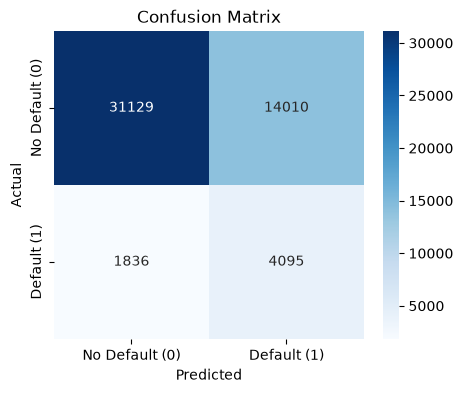

In [5]:
y_pred_proba = model.predict_proba(X_test)[:, 1]

threshold = 0.50
y_pred = (y_pred_proba >= threshold).astype(int)

print(f"--- Classification Report (Threshold = {threshold}) ---")
print(classification_report(y_test, y_pred))

roc_auc = roc_auc_score(y_test, y_pred_proba)
print(f"ROC-AUC Score: {roc_auc:.4f}")

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Default (0)', 'Default (1)'],
            yticklabels=['No Default (0)', 'Default (1)'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix')
plt.show()

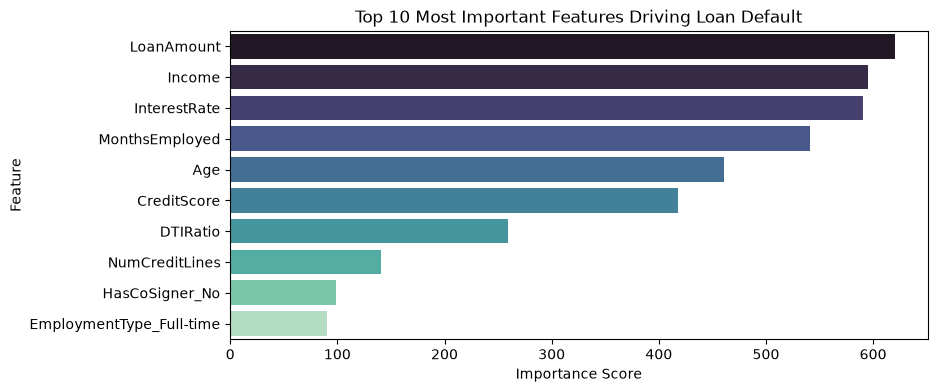

In [6]:
ohe=model.named_steps['preprocessor'].named_transformers_['cat'].named_steps['onehot']
cat_encoded_names = ohe.get_feature_names_out(categorical_features).tolist()
all_features = numeric_features + cat_encoded_names

importances = model.named_steps['classifier'].feature_importances_
importance_df = pd.DataFrame({
    'Feature': all_features,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(9, 4))
sns.barplot(
    data=importance_df.head(10), 
    x='Importance', 
    y='Feature', 
    hue='Feature', 
    palette='mako', 
    legend=False
)
plt.title('Top 10 Most Important Features Driving Loan Default')
plt.xlabel('Importance Score')
plt.ylabel('Feature')
plt.show()

In [7]:
from sklearn.base import BaseEstimator, TransformerMixin

# 1. Custom Transformer for In-Pipeline Feature Engineering
class CreditFeatureEngineer(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()
        X['LoanToIncome'] = X['LoanAmount'] / (X['Income'] + 1e-6)
        
        monthly_rate = (X['InterestRate'] / 100.0) / 12.0
        X['EstimatedMonthlyPayment'] = (X['LoanAmount'] * monthly_rate) / (1 - (1 + monthly_rate) ** (-X['LoanTerm']) + 1e-6)
        X['PaymentToIncomeRatio'] = X['EstimatedMonthlyPayment'] / ((X['Income'] / 12.0) + 1e-6)
        
        X['CreditScoreTier'] = pd.cut(
            X['CreditScore'],
            bins=[-np.inf, 579, 669, 739, 799, np.inf],
            labels=['Poor', 'Fair', 'Good', 'Very Good', 'Exceptional']
        ).astype(str)
        return X

# 2. 3-Way Split: Train (70%), Validation (15%), Test (15%)
X = df.drop(columns=['Default'])
y = df['Default']

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

# 3. Assemble Pipeline
raw_num = ['Age', 'Income', 'LoanAmount', 'CreditScore', 'MonthsEmployed', 'NumCreditLines', 'InterestRate', 'LoanTerm', 'DTIRatio']
eng_num = ['LoanToIncome', 'EstimatedMonthlyPayment', 'PaymentToIncomeRatio']
all_num = raw_num + eng_num

cat_cols = ['Education', 'EmploymentType', 'MaritalStatus', 'HasMortgage', 'HasDependents', 'LoanPurpose', 'HasCoSigner', 'CreditScoreTier']

preprocessor_pipeline = ColumnTransformer(
    transformers=[
        ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), all_num),
        ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), cat_cols)
    ]
)

pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

pipeline = Pipeline(steps=[
    ('engineer', CreditFeatureEngineer()),
    ('preprocessor', preprocessor_pipeline),
    ('classifier', LGBMClassifier(n_estimators=150, learning_rate=0.05, scale_pos_weight=pos_weight, random_state=42, n_jobs=-1, verbose=-1))
])

print("Training pipeline...")
pipeline.fit(X_train, y_train)
print("Pipeline fitted successfully!")

Training pipeline...
Pipeline fitted successfully!


In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import (
    accuracy_score, recall_score, precision_score, f1_score,
    roc_auc_score, average_precision_score
)

# Compare models using the same feature-engineering and preprocessing steps
models_dict = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000, class_weight="balanced", random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, class_weight="balanced",
        random_state=42, n_jobs=-1
    ),
    "LightGBM": LGBMClassifier(
        n_estimators=150, learning_rate=0.05,
        scale_pos_weight=pos_weight, random_state=42,
        n_jobs=-1, verbosity=-1
    )
}

results = []
fitted_models = {}

for name, clf in models_dict.items():
    print(f"Training {name}...")

    pipe = Pipeline(steps=[
        ("engineer", CreditFeatureEngineer()),
        ("preprocessor", preprocessor_pipeline),
        ("classifier", clf)
    ])

    pipe.fit(X_train, y_train)

    # Use validation data for model comparison; reserve test data for final evaluation
    y_val_pred = pipe.predict(X_val)
    y_val_prob = pipe.predict_proba(X_val)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": round(accuracy_score(y_val, y_val_pred), 4),
        "Recall (Default)": round(recall_score(y_val, y_val_pred, zero_division=0), 4),
        "Precision (Default)": round(precision_score(y_val, y_val_pred, zero_division=0), 4),
        "F1-Score": round(f1_score(y_val, y_val_pred, zero_division=0), 4),
        "ROC-AUC": round(roc_auc_score(y_val, y_val_prob), 4),
        "Average Precision": round(average_precision_score(y_val, y_val_prob), 4)
    })

    fitted_models[name] = pipe

comparison_df = pd.DataFrame(results).sort_values(
    by="Average Precision", ascending=False
).reset_index(drop=True)

print("\n--- Validation Model Benchmark Comparison ---")
display(comparison_df)

best_model_name = comparison_df.loc[0, "Model"]
best_model = fitted_models[best_model_name]
print("\nBest model based on validation Average Precision:", best_model_name)

# Evaluate only the selected model on the untouched test set
y_test_pred = best_model.predict(X_test)
y_test_prob = best_model.predict_proba(X_test)[:, 1]

test_results_df = pd.DataFrame([{
    "Model": best_model_name,
    "Accuracy": round(accuracy_score(y_test, y_test_pred), 4),
    "Recall (Default)": round(recall_score(y_test, y_test_pred, zero_division=0), 4),
    "Precision (Default)": round(precision_score(y_test, y_test_pred, zero_division=0), 4),
    "F1-Score": round(f1_score(y_test, y_test_pred, zero_division=0), 4),
    "ROC-AUC": round(roc_auc_score(y_test, y_test_prob), 4),
    "Average Precision": round(average_precision_score(y_test, y_test_prob), 4)
}])

print("\n--- Final Test Results for Selected Model ---")
display(test_results_df)

comparison_df.to_csv("model_validation_comparison.csv", index=False)
test_results_df.to_csv("best_model_test_results.csv", index=False)
print("Model comparison reports saved.")


Training Logistic Regression...
Training Random Forest...
Training LightGBM...

--- Validation Model Benchmark Comparison ---


,Model,Accuracy,Recall (Default),Precision (Default),F1-Score,ROC-AUC,Average Precision
0,Logistic Regression,0.6903,0.6945,0.2273,0.3425,0.7590,0.3343
1,LightGBM,0.6908,0.6819,0.2253,0.3387,0.7556,0.3298
2,Random Forest,0.8796,0.1612,0.4487,0.2372,0.7388,0.3033



Best model based on validation Average Precision: Logistic Regression

--- Final Test Results for Selected Model ---


,Model,Accuracy,Recall (Default),Precision (Default),F1-Score,ROC-AUC,Average Precision
0,Logistic Regression,0.6936,0.6976,0.23,0.3459,0.7659,0.3392


Model comparison reports saved.


In [9]:
COST_FN = 10000
COST_FP = 1000

def compute_business_loss(y_true, y_prob, threshold):
    preds = (y_prob >= threshold).astype(int)
    cm = confusion_matrix(y_true, preds)
    fn = cm[1, 0]
    fp = cm[0, 1]
    return (fn * COST_FN) + (fp * COST_FP)

# 1. Evaluate threshold STRICTLY on the VALIDATION set (fixes data leakage)
val_probs = pipeline.predict_proba(X_val)[:, 1]

thresholds = np.linspace(0.1, 0.9, 17)
costs = [compute_business_loss(y_val, val_probs, t) for t in thresholds]

optimal_t = float(thresholds[np.argmin(costs)])
print(f"Optimal Business Decision Threshold (Validation Set): {optimal_t:.2f} (Lowest Financial Loss)")

# 2. Final unbiased evaluation on the untouched TEST set using optimal_t
test_probs = pipeline.predict_proba(X_test)[:, 1]
test_preds = (test_probs >= optimal_t).astype(int)

print(f"\nTest Set ROC-AUC Score: {roc_auc_score(y_test, test_probs):.4f}")
print("Test Set Classification Report at Optimal Threshold:")
print(classification_report(y_test, test_preds))

Optimal Business Decision Threshold (Validation Set): 0.40 (Lowest Financial Loss)

Test Set ROC-AUC Score: 0.7618
Test Set Classification Report at Optimal Threshold:
              precision    recall  f1-score   support

           0       0.96      0.54      0.69     33855
           1       0.19      0.82      0.31      4448

    accuracy                           0.57     38303
   macro avg       0.57      0.68      0.50     38303
weighted avg       0.87      0.57      0.65     38303



In [10]:
import joblib

# Use the existing end-to-end pipeline, which includes feature engineering,
# preprocessing, and the LightGBM classifier.
# The earlier threshold-selection cell defines optimal_t.
best_pipeline = Pipeline(steps=[
    ("engineer", CreditFeatureEngineer()),
    ("preprocessor", preprocessor_pipeline),
    ("classifier", models_dict["LightGBM"])
])

best_pipeline.fit(X_train, y_train)

joblib.dump(best_pipeline, "loan_default_model.pkl")
print("Model saved to 'loan_default_model.pkl'!")

def predict_loan_application(applicant_data: dict, risk_threshold: float = optimal_t):
    model_loaded = joblib.load("loan_default_model.pkl")
    input_df = pd.DataFrame([applicant_data])

    default_prob = model_loaded.predict_proba(input_df)[0, 1]
    prediction = int(default_prob >= risk_threshold)

    return {
        "status": "success",
        "default_probability": round(float(default_prob), 4),
        "risk_decision": "REJECT / HIGH RISK" if prediction == 1 else "APPROVE / LOW RISK",
        "threshold_used": risk_threshold
    }

sample_applicant = {
    "Age": 28,
    "Income": 32000,
    "LoanAmount": 25000,
    "CreditScore": 590,
    "MonthsEmployed": 12,
    "NumCreditLines": 6,
    "InterestRate": 18.5,
    "LoanTerm": 36,
    "DTIRatio": 0.55,
    "Education": "Bachelor's",
    "EmploymentType": "Unemployed",
    "MaritalStatus": "Single",
    "HasMortgage": "No",
    "HasDependents": "No",
    "LoanPurpose": "Auto",
    "HasCoSigner": "No"
}

api_response = predict_loan_application(sample_applicant)
print("\nAPI Response Output:")
print(api_response)


Model saved to 'loan_default_model.pkl'!

API Response Output:
{'status': 'success', 'default_probability': 0.7604, 'risk_decision': 'REJECT / HIGH RISK', 'threshold_used': 0.4}
